# 04 · Resultado do modelo: comparação, limiar e alvo

**Painel de Equidade em Saúde do Recife** · Projeto 3 + Machine Learning I

> ⚠️ **Base sintética** (ver `docs/contrato_dados.md`).

Este notebook responde ao ponto 1 do feedback do SR1:

1. F1 e recall do modelo da pipeline frente à persistência
2. Comparação com alternativas (KNN, árvore de decisão, random forest)
3. Justificativa do limiar de 0,5
4. Por que o alvo é relativo (as 25% piores) e não uma meta absoluta de completude
5. Quanto da persistência alta vem da regra do gerador sintético

Os números vêm de `src/modelos.py`, que usa **os mesmos dados, variáveis, modelo, limiar e divisão da pipeline** (`src/pipeline.py`). Por isso o F1 da regressão logística aqui é o mesmo da aba *Pipeline* do app. Rode `python src/modelos.py` antes deste notebook: ele grava os CSVs em `notebooks/resultados/` e registra cada execução no MLflow.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ / "src"))
from modelos import COMPLEXIDADE, META_ABSOLUTA

RES = RAIZ / "notebooks" / "resultados"
FIGURAS = RAIZ / "notebooks" / "figuras"
AZUL, LARANJA, VERDE_AGUA, AMARELO = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
CINZA, TEXTO, TEXTO_2, FUNDO = "#b5b4ae", "#0b0b0b", "#52514e", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": FUNDO, "axes.facecolor": FUNDO, "savefig.facecolor": FUNDO,
    "axes.edgecolor": CINZA, "axes.labelcolor": TEXTO_2, "xtick.color": TEXTO_2, "ytick.color": TEXTO_2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e8e7e3",
    "grid.linewidth": 0.8, "axes.axisbelow": True, "font.size": 10, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "figure.dpi": 110,
})
salvar = lambda fig, nome: fig.savefig(FIGURAS / f"{nome}.png", dpi=150, bbox_inches="tight")

modelos = pd.read_csv(RES / "modelos.csv", index_col="modelo")
limiar = pd.read_csv(RES / "limiar.csv", index_col="limiar")
alvo = pd.read_csv(RES / "alvo.csv", index_col="quadrimestre")
persistencia = pd.read_csv(RES / "persistencia.csv", index_col="quadrimestre")
coeficientes = pd.read_csv(RES / "coeficientes.csv", index_col=0)

## 1. Como a comparação foi feita

- **Mesma divisão temporal da pipeline:** treino com os quadrimestres antigos (alvos até 2025.3), teste com os 2 mais recentes que têm resultado conhecido (alvos de 2026.1 e 2026.2). Nada do teste entra no treino.
- **Hiperparâmetros com `GridSearchCV`**, mas com `cv` **temporal**: cada fold treina com o passado e valida no quadrimestre seguinte, sempre dentro do treino. O `cv=5` comum sortearia linhas e deixaria o modelo aprender com o futuro de uma equipe.
- **Regressão logística** entra como está na pipeline (`StandardScaler` + `LogisticRegression`), sem ajuste.
- **Janela móvel:** além do teste fixo, cada modelo é treinado e testado de novo em 3 quadrimestres diferentes (sempre treino no passado). Mostra se o resultado se sustenta e dá o **desvio padrão** usado na decisão.
- **Métrica principal: F1** (equilíbrio entre achar as críticas e não dar alarme falso). A acurácia não serve: "ninguém é crítica" acerta 75%.

In [2]:
colunas = ["f1", "recall", "precisao", "roc_auc", "equipes_alertadas", "janela_f1", "janela_f1_desvio", "hiperparametros"]
modelos[colunas]

,f1,recall,precisao,roc_auc,equipes_alertadas,janela_f1,janela_f1_desvio,hiperparametros
modelo,,,,,,,,
Persistência (baseline),0.833,0.833,0.833,NaN,192,0.830,0.010,NaN
Regressão logística (pipeline),0.852,0.885,0.821,0.970,207,0.844,0.012,NaN
KNN,0.830,0.828,0.832,0.957,191,0.832,0.022,"{'n_neighbors': 15, 'weights': 'distance'}"
Árvore de decisão,0.830,0.839,0.821,0.963,196,0.807,0.030,"{'max_depth': 3, 'min_samples_leaf': 50}"
Random Forest,0.851,0.891,0.814,0.970,210,0.838,0.013,"{'max_depth': 5, 'min_samples_leaf': 1}"


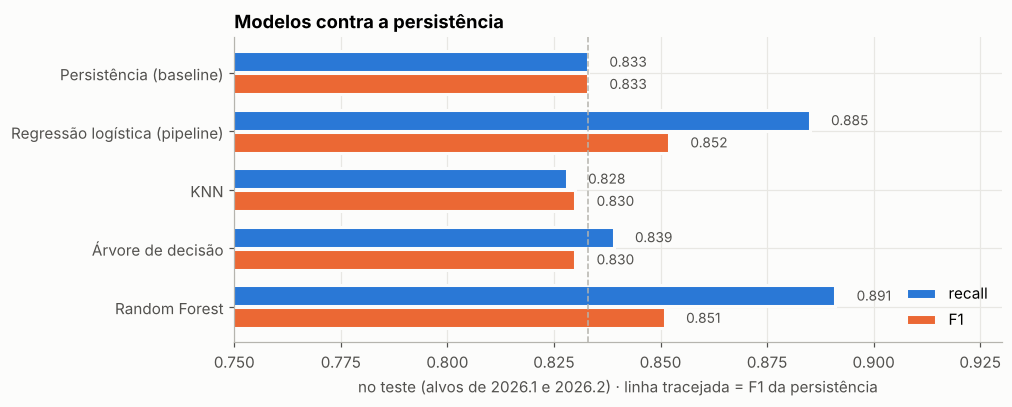

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.6))
y = np.arange(len(modelos))
ax.barh(y - 0.19, modelos["recall"], height=0.36, color=AZUL, edgecolor=FUNDO, linewidth=2, label="recall")
ax.barh(y + 0.19, modelos["f1"], height=0.36, color=LARANJA, edgecolor=FUNDO, linewidth=2, label="F1")
for i, (r, f) in enumerate(zip(modelos["recall"], modelos["f1"])):
    ax.text(r + 0.005, i - 0.19, f"{r:.3f}", va="center", fontsize=9, color=TEXTO_2)
    ax.text(f + 0.005, i + 0.19, f"{f:.3f}", va="center", fontsize=9, color=TEXTO_2)
ax.axvline(modelos.loc["Persistência (baseline)", "f1"], color=CINZA, ls="--", lw=1)
ax.set_yticks(y, modelos.index)
ax.invert_yaxis()
ax.set_xlim(0.75, 0.93)
ax.set_xlabel("no teste (alvos de 2026.1 e 2026.2) · linha tracejada = F1 da persistência")
ax.set_title("Modelos contra a persistência")
ax.legend(loc="lower right", frameon=False)
salvar(fig, "11_modelos_vs_persistencia")

In [4]:
# Decisão tomada por src/modelos.py com os valores sem arredondamento (função escolher)
empatados = modelos.index[modelos["empate_tecnico"]]
print("Superam a persistência na janela móvel e ficam a até 1 desvio do melhor:", ", ".join(empatados))
print("Complexidade:", {n: COMPLEXIDADE[n] for n in empatados})
print("Escolhido:", modelos.index[modelos["escolhido"]][0])

Superam a persistência na janela móvel e ficam a até 1 desvio do melhor: Regressão logística (pipeline), Random Forest
Complexidade: {'Regressão logística (pipeline)': 1, 'Random Forest': 3}
Escolhido: Regressão logística (pipeline)


**Leitura e decisão:**
- A **regressão logística** da pipeline tem **F1 0,852 e recall 0,885** contra **0,833 / 0,833 da persistência**: encontra 170 das 192 equipes que ficaram críticas, contra 160 da persistência, ao custo de 15 alertas a mais (207 contra 192). Na janela móvel o ganho se mantém (0,844 contra 0,830).
- A **árvore de decisão** (melhor combinação: profundidade 3) fica **abaixo da persistência** na janela móvel (0,807): descartada.
- O **KNN** fica no nível da persistência (0,830 no teste, 0,832 na janela): não justifica a troca.
- A **random forest** chega perto da regressão logística (0,851 no teste, 0,838 na janela) e fica dentro de 1 desvio padrão dela: **empate técnico**.
- **Regra de escolha:** entre os modelos que superam a persistência, os que estão a até 1 desvio padrão do melhor são empate técnico; nesse caso fica o mais simples. A regressão logística é mais fácil de explicar à Secretaria (cada variável tem um peso), é mais leve para rodar a cada importação e já está validada. **Ela continua sendo o modelo da pipeline.**
- O ganho sobre a persistência é pequeno (cerca de 2 pontos de F1). O valor do modelo está em **antecipar equipes que ainda não são críticas** (a persistência, por definição, nunca faz isso) e em dar uma **probabilidade** para ordenar a fila de apoio, não só um sim/não.

### Como a regressão logística decide

Apesar do nome, ela é um modelo de **classificação**. Faz uma conta parecida com a regressão linear (soma das variáveis, cada uma com um peso) e passa o resultado por uma curva em S, a **sigmoide**, que leva qualquer número para o intervalo de 0 a 1:

$$P(\text{crítica em } t+1) = \frac{1}{1 + e^{-(b_0 + b_1 x_1 + \dots + b_n x_n)}}$$

Essa probabilidade é o **risco** que o painel mostra; a partir de 0,5 a equipe vira alerta. Como as variáveis passam antes pelo `StandardScaler`, os pesos são comparáveis entre si: **peso negativo diminui o risco, positivo aumenta**, e quanto maior em módulo, mais a variável pesa.

In [5]:
coeficientes.head(8).round(2)

,peso
posicao_na_rede,-1.33
os_preenchido,-0.73
os_nao_perguntado,0.64
os_recusou,-0.44
media_historica,-0.30
indice_anterior,-0.28
indice_completude,-0.26
inconsistencia_raca,0.24


**Leitura:**
- O que mais pesa é a **posição da equipe na rede agora** (`posicao_na_rede`, peso negativo: quanto melhor a posição, menor o risco). Faz sentido, porque o alvo é "estar entre as 25% piores".
- Em seguida vêm os campos de **orientação sexual**: perguntar e registrar (`os_preenchido`) reduz o risco; **não perguntar** (`os_nao_perguntado`) aumenta. É o principal campo que separa as equipes.
- O **histórico** (`media_historica`, `indice_anterior`) também reduz o risco: equipes que sempre foram bem tendem a continuar.
- Cuidado ao ler variável por variável: várias delas medem quase a mesma coisa (`posicao_na_rede`, `indice_completude`, `critica`), e o peso se divide entre elas. Por isso `critica` aparece com peso pequeno e até negativo: a informação dela já está em `posicao_na_rede`. O que vale é o conjunto.

## 2. O limiar de 0,5

O modelo dá uma probabilidade; o limiar decide a partir de quanto a equipe vira alerta. O limiar foi avaliado **na validação temporal** (folds do treino), que é onde se escolhe; o teste aparece só para conferir.

,f1_validacao,recall_validacao,precisao_validacao,f1_teste,alertadas_teste
limiar,,,,,
0.30,0.801,0.943,0.696,0.823,248
0.35,0.818,0.922,0.735,0.837,238
0.40,0.811,0.885,0.749,0.846,224
0.45,0.812,0.859,0.771,0.849,218
0.50,0.811,0.828,0.796,0.852,207
0.55,0.798,0.786,0.812,0.838,197
0.60,0.778,0.734,0.831,0.835,184


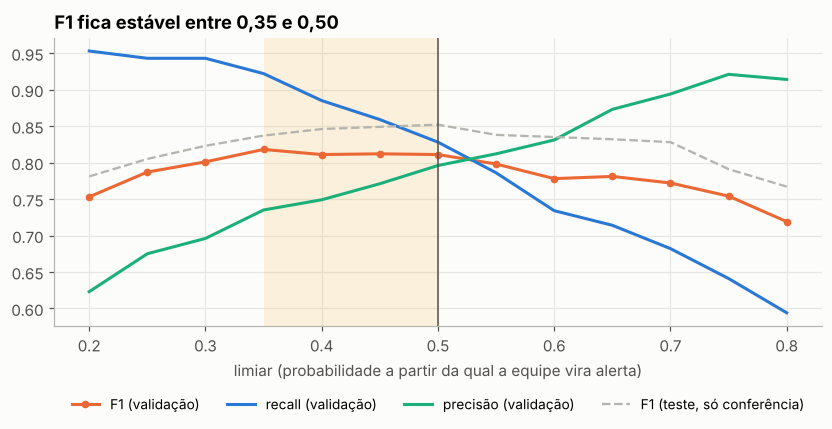

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(limiar.index, limiar["f1_validacao"], color=LARANJA, lw=2, marker="o", ms=4, label="F1 (validação)")
ax.plot(limiar.index, limiar["recall_validacao"], color=AZUL, lw=2, label="recall (validação)")
ax.plot(limiar.index, limiar["precisao_validacao"], color=VERDE_AGUA, lw=2, label="precisão (validação)")
ax.plot(limiar.index, limiar["f1_teste"], color=CINZA, lw=1.5, ls="--", label="F1 (teste, só conferência)")
ax.axvspan(0.35, 0.50, color=AMARELO, alpha=0.12, lw=0)
ax.axvline(0.5, color=TEXTO_2, lw=1)
ax.set_xlabel("limiar (probabilidade a partir da qual a equipe vira alerta)")
ax.set_title("F1 fica estável entre 0,35 e 0,50")
ax.legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.2), fontsize=9)
salvar(fig, "12_limiar")
limiar.loc[[0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6]]

**Por que 0,5:**
- **O F1 é praticamente o mesmo entre 0,35 e 0,50** (0,811 a 0,818 na validação). O resultado não depende de um ajuste fino do limiar, e escolher o pico exato da validação seria ajustar demais a poucos quadrimestres.
- **0,5 tem leitura direta:** a equipe entra em alerta quando é **mais provável ficar crítica do que não ficar**.
- **O número de alertas fica perto da capacidade de apoio:** com 0,5, 207 alertas para 192 críticas reais no teste. Abaixo de 0,35 o recall sobe pouco e os alertas crescem rápido (248 em 0,30, 282 em 0,20), o que dilui o apoio dos distritos. Acima de 0,55 o recall cai rápido.
- Se a Secretaria preferir **não perder nenhuma equipe**, mesmo com mais alarmes, 0,35 é uma alternativa defensável com o mesmo F1 (recall 0,92 na validação).

## 3. Alvo relativo (as 25% piores) x meta absoluta

A regra "crítica = entre as 25% piores do quadrimestre" fixa a proporção de críticas em 25% **por construção**. A alternativa seria uma meta absoluta, por exemplo "crítica = índice de completude abaixo de 50".

,equipes,indice_mediano,pct_abaixo_da_meta,pct_criticas_relativo
quadrimestre,,,,
2024.1,384,60.6,15.9,25.0
2024.2,384,61.2,18.8,25.0
2024.3,384,60.6,19.8,25.0
2025.1,384,61.0,19.0,25.0
2025.2,384,61.3,22.7,25.0
2025.3,384,60.5,25.8,25.0
2026.1,384,61.6,24.5,25.0
2026.2,384,60.9,26.3,25.0


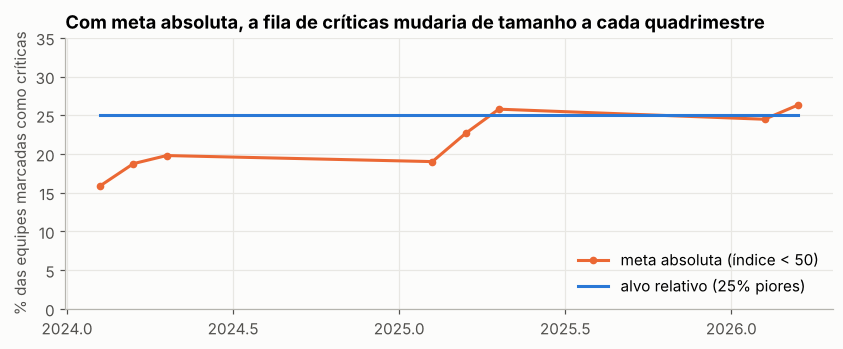

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(alvo.index, alvo["pct_abaixo_da_meta"], color=LARANJA, lw=2, marker="o", ms=4, label=f"meta absoluta (índice < {META_ABSOLUTA})")
ax.plot(alvo.index, alvo["pct_criticas_relativo"], color=AZUL, lw=2, label="alvo relativo (25% piores)")
ax.set_ylim(0, 35)
ax.set_ylabel("% das equipes marcadas como críticas")
ax.set_title("Com meta absoluta, a fila de críticas mudaria de tamanho a cada quadrimestre")
ax.legend(frameon=False, loc="lower right")
salvar(fig, "13_alvo_relativo_x_absoluto")
alvo.round(1)

**Por que o alvo é relativo:**
- **O uso do painel é priorizar apoio com capacidade fixa:** cada distrito tem um apoiador com horas por semana (é o que `pr_agendar_apoio` distribui). A pergunta da Secretaria é "quais equipes atender primeiro", e isso é uma ordenação. Com a meta absoluta, a fila iria de 16% para 26% das equipes no período, sem relação com a capacidade de atender.
- **O alvo fica equilibrado e estável para o modelo:** 25% de positivos em todo quadrimestre, tanto no treino quanto no teste.
- **Limitação, que assumimos:** com o alvo relativo, **sempre haverá 25% de críticas**, mesmo que a rede inteira melhore. Por isso ele **não mede evolução da rede**. Para isso o painel mostra o **índice de completude** (mediana da rede e de cada distrito), que é absoluto. Os dois se complementam: o índice responde "a rede está melhorando?", o alvo relativo responde "quem precisa de apoio agora?".
- O 50 usado aqui é só um exemplo: não existe hoje uma meta oficial de completude da Secretaria. Se ela for definida, a meta absoluta pode virar um segundo alerta.

## 4. Dados sintéticos e a persistência alta

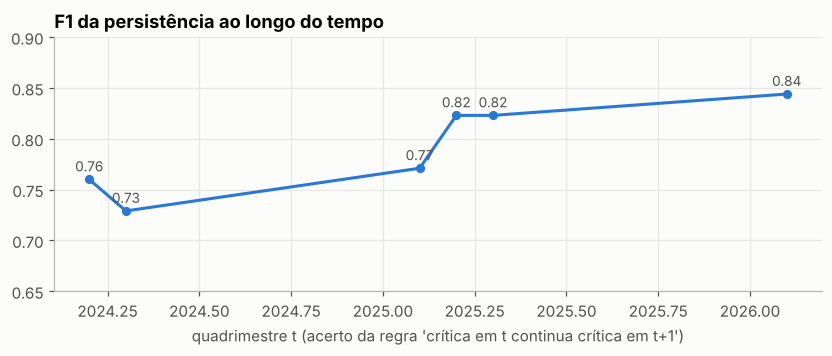

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.0))
ax.plot(persistencia.index, persistencia["f1_persistencia"], color=AZUL, lw=2, marker="o", ms=5)
for q, v in persistencia["f1_persistencia"].items():
    ax.text(q, v + 0.008, f"{v:.2f}", ha="center", fontsize=9, color=TEXTO_2)
ax.set_ylim(0.65, 0.9)
ax.set_xlabel("quadrimestre t (acerto da regra 'crítica em t continua crítica em t+1')")
ax.set_title("F1 da persistência ao longo do tempo")
salvar(fig, "14_persistencia_no_tempo")

**Reconhecendo o limite dos dados:**
- A base é **gerada por código** (`src/gerar_sintetico.py`). No gerador, cada equipe tem um **jeito próprio de preencher** que muda devagar: `nível = média da equipe + tendência + 0,6 × desvio do período anterior + ruído`. Ou seja, **a persistência foi colocada nos dados pela própria regra do gerador**.
- Por isso a persistência é tão forte (F1 de 0,73 a 0,84) e **sobe ao longo do tempo**: conforme as tendências de cada equipe acumulam, as equipes se afastam da linha de corte e trocam menos de lado.
- Consequência: **o 0,83 da persistência e o 0,85 do modelo valem para esta base**, não são uma previsão do desempenho com dados reais. Com os dados do PEC, as equipes podem mudar mais (troca de profissionais, mutirões), a persistência tende a cair e o ganho do modelo pode ser maior ou menor.
- O que **não depende do gerador** e vale levar para os dados reais é o **método**: divisão temporal, baseline de persistência como régua, comparação com alternativas, escolha do limiar na validação e o registro de tudo no MLflow. Quando a extração real existir, basta rodar `python src/modelos.py` de novo.

## 5. Registro no MLflow

Cada execução de `src/modelos.py` cria, no experimento `risco-equipe-critica`:

| Run | O que guarda |
|---|---|
| `comparacao` (pai) | Tags `decisao` (modelo escolhido) e `empate_tecnico`; os 4 CSVs deste notebook como artefatos |
| Um run por modelo | Hiperparâmetros, F1, recall, precisão, ROC-AUC, F1 da janela móvel e desvio; o modelo treinado |
| Um run por combinação do GridSearch | Hiperparâmetros e F1 médio e desvio na validação temporal |

```bash
pip install -r requirements-ml.txt
python src/modelos.py
mlflow ui --backend-store-uri sqlite:///mlflow.db --host 127.0.0.1 --port 5001
```

Com Docker, `docker compose up -d` sobe o servidor do MLflow em `http://127.0.0.1:5001` (rodar o script com `MLFLOW_TRACKING_URI=http://127.0.0.1:5001`).

O MLflow é a ferramenta do **experimento**. A **pipeline do app não depende dele**: o Streamlit Cloud não alcança um servidor MLflow, então cada execução da pipeline continua registrando o F1 do modelo e da persistência na tabela `execucao_pipeline` do banco (aba *Pipeline*).